In [1]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip -q install -U "pip<25" "setuptools<75" "wheel"
!pip -q install --force-reinstall --no-cache-dir "numpy==2.2.2" "scipy==1.13.1"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 175.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.2/38.2 MB 271.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
access 1.1.10.post3 requires scipy>=1.14.1, but you have scipy 1.13.1 which is incompatible.
tensorflow 2.19.0 requires numpy<2.2.0,>=1.26.0, but you have numpy 2.2.2 which is incompatible.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.2.2 which is incompatible.
tsfresh 0.21.1 requires scipy>=1.14.0; python_version >= "3.10", but you have scipy 1.13.1 which is incompatible.


In [3]:
!pip -q install shap

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
access 1.1.10.post3 requires scipy>=1.14.1, but you have scipy 1.13.1 which is incompatible.
tsfresh 0.21.1 requires scipy>=1.14.0; python_version >= "3.10", but you have scipy 1.13.1 which is incompatible.


In [4]:
import os, glob
import json
import random
import numpy as np
import shap, numpy as np
import pandas as pd
import shap
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from typing import Dict, Tuple, Optional
from datetime import datetime

In [5]:
print("torch:", torch.__version__)
print("shap:", shap.__version__)
print("numpy:", np.__version__)
print("cuda available:", torch.cuda.is_available())

torch: 2.9.0+cpu
shap: 0.50.0
numpy: 2.0.2
cuda available: False


In [6]:
# Canonical paths
base_dir = "/content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M"
preprocessed_dir = f"{base_dir}/AntM2C_preprocessed"
checkpoints_dir = f"{base_dir}/checkpoints"
splits_dir = f"{preprocessed_dir}/splits"
split_features_dir = f"{preprocessed_dir}/split_features"

results_dir = f"{base_dir}/eval_results"
explain_dir = os.path.join(results_dir, "explainability")
os.makedirs(explain_dir, exist_ok=True)

In [7]:
print("--- Paths resolved: ---")
print(" base_dir:", base_dir)
print(" preprocessed_dir:", preprocessed_dir)
print(" checkpoints_dir:", checkpoints_dir)
print(" results_dir:", results_dir)
print(" explain_dir:", explain_dir)

--- Paths resolved: ---
 base_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M
 preprocessed_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/AntM2C_preprocessed
 checkpoints_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/checkpoints
 results_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results
 explain_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/explainability


In [8]:
# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Determinism flags (safe defaults)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [9]:
# Device
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cpu


In [10]:
# Load configs + checkpoint + predictions
fusion_config_path = os.path.join(checkpoints_dir, "fusion_config.json")
meta_config_path = os.path.join(checkpoints_dir, "meta_config.json")
model_ckpt_path = os.path.join(checkpoints_dir, "coldfusionx_model_epoch3.pt")

pred_path = os.path.join(results_dir, "test_predictions.npz")

In [11]:
# Load JSON configs
with open(fusion_config_path, "r") as f:
    fusion_config = json.load(f)

with open(meta_config_path, "r") as f:
    meta_config = json.load(f)

# Load predictions (Notebook 09 output)
pred_data = np.load(pred_path)
pred_keys = list(pred_data.keys())

In [12]:
print("--- Loaded Artifacts ---")
print("fusion_config_path:", fusion_config_path)
print("meta_config_path:", meta_config_path)
print("model_ckpt_path:", model_ckpt_path)
print("pred_path:", pred_path)
print("pred_keys:", pred_keys)

# Print key values (audit-friendly)
print("\n--- Key Config Values ---")
print("d_model:", fusion_config.get("d_model"))
print("hidden_dim:", fusion_config.get("hidden_dim"))
print("num_experts:", fusion_config.get("num_experts"))
print("num_scenes:", fusion_config.get("num_scenes"))
print("FEWSHOT_N:", meta_config.get("FEWSHOT_N"))

--- Loaded Artifacts ---
fusion_config_path: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/checkpoints/fusion_config.json
meta_config_path: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/checkpoints/meta_config.json
model_ckpt_path: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/checkpoints/coldfusionx_model_epoch3.pt
pred_path: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/test_predictions.npz
pred_keys: ['y_true', 'y_logit', 'y_prob', 'cold_mask', 'scene_idx', 'alpha', 'gates']

--- Key Config Values ---
d_model: 256
hidden_dim: 256
num_experts: 4
num_scenes: 5
FEWSHOT_N: 10


In [13]:
# Quick sanity on predictions shapes
print("--- Prediction Array Shapes ---")
for k in ["y_true", "y_logit", "y_prob", "cold_mask", "scene_idx", "alpha"]:
    if k in pred_data:
        arr = pred_data[k]
        print(f"{k:10s}: {arr.shape} | dtype={arr.dtype}")

--- Prediction Array Shapes ---
y_true    : (373033,) | dtype=float32
y_logit   : (373033,) | dtype=float32
y_prob    : (373033,) | dtype=float32
cold_mask : (373033,) | dtype=bool
scene_idx : (373033,) | dtype=int64
alpha     : (373033, 1) | dtype=float32


 #### Load Predictions + Build a “Selection Table”

In [14]:
# Load arrays from test_predictions.npz
y_true = pred_data["y_true"].astype(np.float32)
y_logit = pred_data["y_logit"].astype(np.float32)
y_prob = pred_data["y_prob"].astype(np.float32)
cold_mask = pred_data["cold_mask"].astype(bool)
scene_idx = pred_data["scene_idx"].astype(np.int64)
alpha = pred_data["alpha"].astype(np.float32).squeeze()   # (N,)

In [15]:
# gates optional
gates = pred_data["gates"].astype(np.float32) if "gates" in pred_data else None  # (N, E)

In [16]:
N = len(y_true)
assert alpha.shape == (N,), f"alpha shape mismatch: {alpha.shape} vs {(N,)}"

In [17]:
# row_idx mapping
test_idx_path = os.path.join(splits_dir, "test_idx.npy")
test_idx = np.load(test_idx_path).astype(np.int64)  # row indices into row-aligned feature stores
assert test_idx.shape[0] == N, f"test_idx mismatch: {test_idx.shape[0]} vs N={N}"

In [18]:
# Basic DataFrame
pred_df = pd.DataFrame({
    "row_idx": test_idx,
    "y_true": y_true,
    "y_logit": y_logit,
    "y_prob": y_prob,
    "cold_mask": cold_mask,
    "scene_idx": scene_idx,
    "alpha": alpha,
})

print("pred_df created:", pred_df.shape)
pred_df.head()

pred_df created: (373033, 7)


,row_idx,y_true,y_logit,y_prob,cold_mask,scene_idx,alpha
0,2296852,0.0,0.321191,0.579614,False,2,1.0
1,495625,1.0,2.395261,0.916465,False,2,1.0
2,2437289,0.0,-2.105106,0.108602,False,3,1.0
3,1517928,0.0,-5.083009,0.006163,False,2,1.0
4,542839,1.0,0.955819,0.722284,False,2,1.0


Add derived columns (TP/FP/TN/FN, confidence, alpha bins, gates diagnostics)

In [19]:
# Derived columns
THRESH = 0.5  # keeping it fixed
y_pred = (pred_df["y_prob"].values >= THRESH).astype(np.int32)
y_true_int = pred_df["y_true"].values.astype(np.int32)

pred_df["y_pred"] = y_pred
pred_df["confidence"] = np.abs(pred_df["y_prob"].values - 0.5).astype(np.float32)

In [20]:
pred_df["is_tp"] = (y_pred == 1) & (y_true_int == 1)
pred_df["is_fp"] = (y_pred == 1) & (y_true_int == 0)
pred_df["is_tn"] = (y_pred == 0) & (y_true_int == 0)
pred_df["is_fn"] = (y_pred == 0) & (y_true_int == 1)

In [21]:
# Expert chosen (argmax) and max weight
pred_df["gate_expert"] = gates.argmax(axis=1).astype(np.int64)
pred_df["gate_max"] = gates.max(axis=1).astype(np.float32)

# Gate entropy (how "confident" the router is)
eps = 1e-12
p = np.clip(gates, eps, 1.0)
entropy = -(p * np.log(p)).sum(axis=1)  # natural log
pred_df["gate_entropy"] = entropy.astype(np.float32)

In [22]:
# Alpha bins (aligns with "meta-driven vs ID-driven" worked on notebook 09)
pred_df["alpha_bin"] = pd.cut(
    pred_df["alpha"],
    bins=[-np.inf, 0.33, 0.66, np.inf],
    labels=["alpha_low", "alpha_mid", "alpha_high"]
).astype(str)

In [23]:
print("Derived columns added.")
pred_df.head()

Derived columns added.


,row_idx,y_true,y_logit,y_prob,cold_mask,scene_idx,alpha,y_pred,confidence,is_tp,is_fp,is_tn,is_fn,gate_expert,gate_max,gate_entropy,alpha_bin
0,2296852,0.0,0.321191,0.579614,False,2,1.0,1,0.079614,False,True,False,False,0,0.316574,1.350762,alpha_high
1,495625,1.0,2.395261,0.916465,False,2,1.0,1,0.416465,True,False,False,False,0,0.316574,1.350762,alpha_high
2,2437289,0.0,-2.105106,0.108602,False,3,1.0,0,0.391398,False,False,True,False,2,0.650946,1.026001,alpha_high
3,1517928,0.0,-5.083009,0.006163,False,2,1.0,0,0.493837,False,False,True,False,0,0.316574,1.350762,alpha_high
4,542839,1.0,0.955819,0.722284,False,2,1.0,1,0.222284,True,False,False,False,0,0.316574,1.350762,alpha_high


#### Selection Table Summary

In [24]:
print("N total:", len(pred_df))
print("Cold rate:", float(pred_df["cold_mask"].mean()))
print("Positive rate:", float(pred_df["y_true"].mean()))

N total: 373033
Cold rate: 0.038975104079263766
Positive rate: 0.3367503583431244


In [25]:
print("--- Counts by cold/warm: ---\n")
print(pred_df.groupby("cold_mask")["y_true"].agg(["count", "mean"]).rename(columns={"mean": "pos_rate"}))

--- Counts by cold/warm: ---

            count  pos_rate
cold_mask                  
False      358494  0.344717
True        14539  0.140312


Cold-start interactions constitute a small but distinct subset (~3.9%) with a substantially lower positive rate, validating the need for specialised cold-start handling within the unified pipeline.

In [26]:
print("--- Counts by scenario: --- \n")
print(pred_df.groupby("scene_idx")["y_true"].agg(["count", "mean"]).rename(columns={"mean": "pos_rate"}))

--- Counts by scenario: --- 

            count  pos_rate
scene_idx                  
0           21682  0.041232
1           91798  0.231726
2          189948  0.467444
3           42514  0.297408
4           27091  0.074527


Interaction volume and outcome vary markedly across scenarios, justifying the use of scenario-aware routing rather than a single shared prediction pathway.

In [27]:
print("--- Counts by alpha_bin: ---\n")
print(pred_df.groupby("alpha_bin")["y_true"].agg(["count", "mean"]).rename(columns={"mean": "pos_rate"}))

--- Counts by alpha_bin: ---

             count  pos_rate
alpha_bin                   
alpha_high  365852  0.340821
alpha_low     4238  0.120340
alpha_mid     2943  0.142372


Most predictions rely heavily on ID-based embeddings (alpha_high), while lower-α cases correspond to colder items where meta-embeddings contribute more strongly.

In [28]:
print("--- Routing summary (expert selection counts): ---\n")
print(pred_df["gate_expert"].value_counts().sort_index())

--- Routing summary (expert selection counts): ---

gate_expert
0    189948
1     91798
2     91287
Name: count, dtype: int64


Multiple experts are actively selected at inference time, indicating that the MMoE router learns differentiated representations rather than collapsing to a single expert.

In [29]:
print("--- Gate max weight summary: ---\n")
print(pred_df["gate_max"].describe())

--- Gate max weight summary: ---

count    373033.000000
mean          0.369072
std           0.105901
min           0.284068
25%           0.316574
50%           0.316574
75%           0.386024
max           0.650946
Name: gate_max, dtype: float64


Gate confidence remains moderate (mean ≈ 0.37), suggesting soft expert mixtures rather than overconfident hard routing, which supports stable generalisation across scenarios.

In [30]:
print("--- Gate entropy summary: ---\n")
print(pred_df["gate_entropy"].describe())

--- Gate entropy summary: ---

count    373033.000000
mean          1.292807
std           0.104611
min           1.026001
25%           1.256635
50%           1.350762
75%           1.350762
max           1.379710
Name: gate_entropy, dtype: float64


High but non-maximal gate entropy indicates controlled uncertainty in expert selection, consistent with smooth scenario-aware routing rather than random or collapsed behaviour.

#### Define Explanation Cohorts (cold/warm + scenario + α regimes)

In [31]:
# Parameters
K_BATCH = 50     # SHAP batch per cohort
K_CASE  = 5      # case studies per cohort

# High-confidence threshold: use top quantile (to avoid arbitrary fixed cutoffs)
CONF_Q = 0.90  # top 10% most confident predictions within a cohort

BEST_SCENE = 1  # from Nb09: strong AUC
WORST_SCENE = 3 # from Nb09: weakest AUC

In [32]:
# Helper: sample with determinism
rng = np.random.default_rng(SEED)

In [33]:
def select_high_conf_subset(df, conf_q=0.90):
    """
    Returns df filtered to rows with confidence >= quantile(conf_q).
    Applied within each cohort to ensure "high-confidence" meaning is cohort-relative.
    """
    thr = df["confidence"].quantile(conf_q)
    return df[df["confidence"] >= thr], float(thr)

In [34]:
def pick_k_rows(df, k, sort_by="confidence", descending=True):
    """
    Deterministic selection:
    - if df larger than k: randomly sample (seeded) or take top-k (for case studies)
    """
    if len(df) == 0:
        return np.array([], dtype=np.int64)
    if sort_by is not None:
        df_sorted = df.sort_values(sort_by, ascending=not descending)
        return df_sorted["row_idx"].head(k).to_numpy(dtype=np.int64)
    # fallback random
    idx = df["row_idx"].to_numpy(dtype=np.int64)
    if len(idx) <= k:
        return idx
    return rng.choice(idx, size=k, replace=False)

In [35]:
def pick_k_random(df, k):
    """Seeded random selection for SHAP batches (avoids only extreme cases)."""
    if len(df) == 0:
        return np.array([], dtype=np.int64)
    idx = df["row_idx"].to_numpy(dtype=np.int64)
    if len(idx) <= k:
        return idx
    return rng.choice(idx, size=k, replace=False)

Build the cohorts and select K=50 + k=5 for each

In [36]:
cohorts = {}

def add_cohort(name, df_cohort):
    """
    For each cohort:
      - filter to high-confidence subset (top CONF_Q quantile)
      - pick K_BATCH random samples for SHAP batch
      - pick K_CASE top-confidence samples for case studies
    """
    df_hc, thr = select_high_conf_subset(df_cohort, conf_q=CONF_Q)

    batch_rows = pick_k_random(df_hc, K_BATCH)
    case_rows  = pick_k_rows(df_hc, K_CASE, sort_by="confidence", descending=True)

    cohorts[name] = {
        "cohort_size": int(len(df_cohort)),
        "high_conf_threshold": thr,
        "high_conf_size": int(len(df_hc)),
        "batch_row_idx": batch_rows.tolist(),
        "case_row_idx": case_rows.tolist(),
    }

Cold and Warm start

In [37]:
# Cold / High-confidence correct
cold_correct = pred_df[(pred_df["cold_mask"]) & ((pred_df["is_tp"]) | (pred_df["is_tn"]))]
add_cohort("cold_highconf_correct", cold_correct)

In [38]:
# Cold / High-confidence wrong
cold_wrong = pred_df[(pred_df["cold_mask"]) & ((pred_df["is_fp"]) | (pred_df["is_fn"]))]
add_cohort("cold_highconf_wrong", cold_wrong)

In [39]:
# Warm / High-confidence correct
warm_correct = pred_df[(~pred_df["cold_mask"]) & ((pred_df["is_tp"]) | (pred_df["is_tn"]))]
add_cohort("warm_highconf_correct", warm_correct)

In [40]:
# Warm / High-confidence wrong
warm_wrong = pred_df[(~pred_df["cold_mask"]) & ((pred_df["is_fp"]) | (pred_df["is_fn"]))]
add_cohort("warm_highconf_wrong", warm_wrong)

Scenario based

In [41]:
# Scenario-specific slices (best vs worst from Nb09)
#    Use all (not restricted to cold/warm), then high-confidence filter inside add_cohort.
scene_best = pred_df[pred_df["scene_idx"] == BEST_SCENE]
add_cohort(f"scene_{BEST_SCENE}_highconf", scene_best)

In [42]:
scene_worst = pred_df[pred_df["scene_idx"] == WORST_SCENE]
add_cohort(f"scene_{WORST_SCENE}_highconf", scene_worst)

Alpha values

In [43]:
# Alpha extremes
alpha_low = pred_df[pred_df["alpha_bin"] == "alpha_low"]
add_cohort("alpha_low_highconf", alpha_low)

In [44]:
alpha_high = pred_df[pred_df["alpha_bin"] == "alpha_high"]
add_cohort("alpha_high_highconf", alpha_high)

In [45]:
print("--- Explainability Cohorts Summary ---")
print(f"Selection: K_BATCH={K_BATCH} per cohort, K_CASE={K_CASE} per cohort")
print(f"High-confidence definition: top {int((1-CONF_Q)*100)}% by confidence within each cohort (quantile={CONF_Q})")
print(f"Scenario slices: BEST_SCENE={BEST_SCENE}, WORST_SCENE={WORST_SCENE}\n")

for name, info in cohorts.items():
    print(f"--- {name} ---")
    print(f"cohort_size:      {info['cohort_size']}")
    print(f"high_conf_thr:    {info['high_conf_threshold']:.4f}")
    print(f"high_conf_size:   {info['high_conf_size']}")
    print(f"batch_row_idx:    {len(info['batch_row_idx'])} selected")
    print(f"case_row_idx:     {len(info['case_row_idx'])} selected")
    print()

--- Explainability Cohorts Summary ---
Selection: K_BATCH=50 per cohort, K_CASE=5 per cohort
High-confidence definition: top 9% by confidence within each cohort (quantile=0.9)
Scenario slices: BEST_SCENE=1, WORST_SCENE=3

--- cold_highconf_correct ---
cohort_size:      12757
high_conf_thr:    0.4964
high_conf_size:   1276
batch_row_idx:    50 selected
case_row_idx:     5 selected

--- cold_highconf_wrong ---
cohort_size:      1782
high_conf_thr:    0.4536
high_conf_size:   179
batch_row_idx:    50 selected
case_row_idx:     5 selected

--- warm_highconf_correct ---
cohort_size:      304776
high_conf_thr:    0.4970
high_conf_size:   30478
batch_row_idx:    50 selected
case_row_idx:     5 selected

--- warm_highconf_wrong ---
cohort_size:      53718
high_conf_thr:    0.4209
high_conf_size:   5372
batch_row_idx:    50 selected
case_row_idx:     5 selected

--- scene_1_highconf ---
cohort_size:      91798
high_conf_thr:    0.4997
high_conf_size:   9180
batch_row_idx:    50 selected
case_ro

In [46]:
# Save JSON (reproducible selection indices for Notebook 10)
out_path = os.path.join(explain_dir, "explainability_sample_indices.json")
with open(out_path, "w") as f:
    json.dump({
        "seed": SEED,
        "K_BATCH": K_BATCH,
        "K_CASE": K_CASE,
        "CONF_Q": CONF_Q,
        "BEST_SCENE": BEST_SCENE,
        "WORST_SCENE": WORST_SCENE,
        "cohorts": cohorts
    }, f, indent=2)

Explainability cohorts were constructed by stratifying test predictions across cold and warm interactions, correctness, scenario difficulty, and α-regimes, and further restricted to high-confidence predictions to ensure stable and interpretable SHAP attributions. Each cohort includes a balanced SHAP batch enabling consistent local and comparative explanations without rerunning predictions.

#### Rebuild Model and Feature Fetch by row_idx

In [47]:
# Paths to aligned artifacts (same as Notebook 09)
df_id_path = os.path.join(split_features_dir, "df_id_encoded.pkl")
text_path  = os.path.join(split_features_dir, "text_embeddings.npy")  # memmap
time_path  = os.path.join(split_features_dir, "time_features_final.pt")

img_emb_path = os.path.join(split_features_dir, "image_embeddings_vit_base_aligned.pt")
img_miss_path = os.path.join(split_features_dir, "image_missing_mask.pt")

train_idx_path = os.path.join(splits_dir, "train_idx.npy")

In [48]:
# Load artifacts
df_id = pd.read_pickle(df_id_path)
text_mem = np.load(text_path, mmap_mode="r")
time_features = torch.load(time_path, map_location="cpu")

image_embeddings = torch.load(img_emb_path, map_location="cpu").float()
image_missing_mask = torch.load(img_miss_path, map_location="cpu").bool()

In [49]:
# Basic checks
N = len(df_id)
assert text_mem.shape[0] == N, f"text rows mismatch: {text_mem.shape[0]} vs {N}"
assert time_features.shape[0] == N, f"time rows mismatch: {time_features.shape[0]} vs {N}"

num_items = int(df_id["item_id_idx"].max()) + 1
assert image_embeddings.shape[0] == num_items, f"image items mismatch: {image_embeddings.shape[0]} vs {num_items}"
assert image_embeddings.shape[1] == 768, f"expected 768 image dim, got {image_embeddings.shape[1]}"

In [50]:
print("--- Feature stores loaded and aligned. ---")
print("N interactions:", N)
print("text_mem:", text_mem.shape, text_mem.dtype)
print("time_features:", tuple(time_features.shape))
print("image_embeddings:", tuple(image_embeddings.shape))
print("image_missing_mask:", tuple(image_missing_mask.shape))
print("num_items:", num_items)

--- Feature stores loaded and aligned. ---
N interactions: 3730329
text_mem: (3730329, 1536) float32
time_features: (3730329, 5)
image_embeddings: (59142, 768)
image_missing_mask: (59142,)
num_items: 59142


In [51]:
# Rebuild train-only item counts (for item_count)
train_idx = np.load(train_idx_path).astype(np.int64)

train_items = df_id.iloc[train_idx]["item_id_idx"].to_numpy(dtype=np.int64)
item_train_count = np.bincount(train_items, minlength=num_items).astype(np.int64)

In [52]:
print("Train-only item counts rebuilt.")
print("train interactions:", len(train_idx))
print("count stats: min={}, median={:.2f}, mean={:.2f}, max={}".format(
    item_train_count.min(),
    float(np.median(item_train_count)),
    float(item_train_count.mean()),
    item_train_count.max()
))

Train-only item counts rebuilt.
train interactions: 2984263
count stats: min=0, median=2.00, mean=50.46, max=401813


In [53]:
# from Notebook 06
class ModalityAttentionFusion(nn.Module):
    """
    Projects {id, text, image, time} into a shared d_model space and applies
    per-sample attention over modalities.

    Forward inputs:
      id_vec:    (B, id_dim)
      text_vec:  (B, text_dim=1536)
      image_vec: (B, image_dim=768)
      time_vec:  (B, time_dim=5 or Time2Vec dim later)

    Output:
      fused: (B, d_model)

    Diagnostics:
      get_last_attention() returns a dict of attention weights.
    """
    def __init__(
        self,
        id_dim: int,
        text_dim: int,
        image_dim: int,
        time_dim: int,
        d_model: int = 256,
        attn_hidden: int = 128,
        dropout: float = 0.1
    ):
        super().__init__()

        # Projections into shared d_model
        self.proj_id = nn.Sequential(
            nn.Linear(id_dim, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.proj_text = nn.Sequential(
            nn.Linear(text_dim, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.proj_image = nn.Sequential(
            nn.Linear(image_dim, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.proj_time = nn.Sequential(
            nn.Linear(time_dim, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

        # Attention MLP produces 1 scalar score per modality per sample
        self.attn_mlp = nn.Sequential(
            nn.Linear(d_model, attn_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(attn_hidden, 1)
        )

        self._last_attention: Optional[Dict[str, torch.Tensor]] = None

    def forward(
        self,
        id_vec: torch.Tensor,
        text_vec: torch.Tensor,
        image_vec: torch.Tensor,
        time_vec: torch.Tensor
    ) -> torch.Tensor:

        # Project each modality to (B, d_model)
        z_id = self.proj_id(id_vec)
        z_text = self.proj_text(text_vec)
        z_image = self.proj_image(image_vec)
        z_time = self.proj_time(time_vec)

        # Stack: (B, M=4, d_model)
        Z = torch.stack([z_id, z_text, z_image, z_time], dim=1)

        # Compute attention logits per modality: (B, 4, 1) -> (B, 4)
        logits = self.attn_mlp(Z).squeeze(-1)

        # Softmax over modalities -> (B, 4)
        attn = F.softmax(logits, dim=1)

        # Weighted sum: (B, 4, 1) * (B, 4, d_model) -> (B, d_model)
        fused = torch.sum(attn.unsqueeze(-1) * Z, dim=1)

        # Save for diagnostics (detach for safe logging)
        self._last_attention = {
            "id": attn[:, 0].detach(),
            "text": attn[:, 1].detach(),
            "image": attn[:, 2].detach(),
            "time": attn[:, 3].detach(),
        }

        return fused

    def get_last_attention(self) -> Optional[Dict[str, torch.Tensor]]:
        return self._last_attention

In [54]:
# from notbook 06
class ScenarioAwareMMoE(nn.Module):
    """
    Scenario-aware Mixture-of-Experts (MMoE).

    Inputs:
      x:        (B, d_model)   fused representation
      scene_idx:(B,)           scenario indices (0..num_scenes-1)

    Outputs:
      y:        (B, hidden_dim) combined expert output

    Diagnostics:
      get_last_gates(): returns gate weights (B, num_experts)
    """
    def __init__(
        self,
        d_model: int,
        hidden_dim: int,
        num_experts: int,
        num_scenes: int,
        gate_embed_dim: int = 16,
        expert_dropout: float = 0.1
    ):
        super().__init__()

        self.d_model = d_model
        self.hidden_dim = hidden_dim
        self.num_experts = num_experts
        self.num_scenes = num_scenes

        # Experts: each expert maps (B, d_model) -> (B, hidden_dim)
        self.experts = nn.ModuleList([
            nn.Sequential(
                nn.Linear(d_model, hidden_dim),
                nn.ReLU(),
                nn.Dropout(expert_dropout),
                nn.Linear(hidden_dim, hidden_dim),
                nn.ReLU(),
                nn.Dropout(expert_dropout),
            )
            for _ in range(num_experts)
        ])

        # Scene embedding used for gating
        self.scene_embed = nn.Embedding(num_scenes, gate_embed_dim)

        # Gate network: conditioned on scene embedding (optionally we can include x too later)
        self.gate = nn.Sequential(
            nn.Linear(gate_embed_dim, gate_embed_dim),
            nn.ReLU(),
            nn.Linear(gate_embed_dim, num_experts)
        )

        self._last_gates: Optional[torch.Tensor] = None

    def forward(self, x: torch.Tensor, scene_idx: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (B, d_model)
            scene_idx: (B,)
        Returns:
            y: (B, hidden_dim)
        """
        B = x.size(0)

        # Expert outputs: list of (B, hidden_dim) -> stack -> (B, E, hidden_dim)
        expert_outputs = torch.stack([expert(x) for expert in self.experts], dim=1)

        # Compute gate weights conditioned on scene_idx
        s_emb = self.scene_embed(scene_idx)           # (B, gate_embed_dim)
        gate_logits = self.gate(s_emb)                # (B, num_experts)
        gates = F.softmax(gate_logits, dim=-1)        # (B, num_experts)

        # Combine experts: (B, E, 1) * (B, E, hidden_dim) -> (B, hidden_dim)
        y = torch.sum(gates.unsqueeze(-1) * expert_outputs, dim=1)

        # Store for diagnostics
        self._last_gates = gates.detach()

        return y

    def get_last_gates(self) -> Optional[torch.Tensor]:
        return self._last_gates

In [55]:
# from notebook 07
class IDEmbeddingLayer(nn.Module):
    """
    Embedding tables for user/item/scene.
    Produces user_emb, item_emb, scene_emb.
    """
    def __init__(self, num_users: int, num_items: int, num_scenes: int,
                 id_dim: int = 256, scene_dim: int = 32, dropout: float = 0.0):
        super().__init__()
        self.user_emb = nn.Embedding(num_users, id_dim)
        self.item_emb = nn.Embedding(num_items, id_dim)
        self.scene_emb = nn.Embedding(num_scenes, scene_dim)

        self.dropout = nn.Dropout(dropout)

    def forward(self, user_idx: torch.Tensor, item_idx: torch.Tensor, scene_idx: torch.Tensor):
        u = self.dropout(self.user_emb(user_idx))
        i = self.dropout(self.item_emb(item_idx))
        s = self.dropout(self.scene_emb(scene_idx))
        return u, i, s

In [56]:
# from notebook 07
class ItemBlendModule(nn.Module):
    """
    Smooth alpha blending based on TRAIN item frequency.

    alpha in [0,1] increases with item exposure count:
      - low count  -> alpha closer to 0 (more meta)
      - high count -> alpha closer to 1 (more ID)
    """
    def __init__(self, fewshot_n: int):
        super().__init__()
        self.fewshot_n = int(fewshot_n)
        self._last_alpha = None

    def forward(
        self,
        item_id_emb: torch.Tensor,     # (B, D)
        item_meta_emb: torch.Tensor,   # (B, D)
        item_count: torch.Tensor       # (B,)
    ) -> torch.Tensor:

        # Smooth alpha: log-scaled by threshold (robust, bounded)
        alpha = torch.log1p(item_count.float()) / np.log1p(self.fewshot_n)
        alpha = torch.clamp(alpha, 0.0, 1.0).unsqueeze(1)  # (B,1)

        item_final = alpha * item_id_emb + (1.0 - alpha) * item_meta_emb
        self._last_alpha = alpha.detach()
        return item_final

    def get_last_alpha(self):
        return self._last_alpha

In [57]:
# from notebook 07
class MetaEmbeddingGenerator(nn.Module):
    """
    Generates meta_item_emb from non-ID modalities: text, image, time
    using projection layers + per-sample modality attention.
    """
    def __init__(
        self,
        text_dim: int,
        image_dim: int,
        time_dim: int,
        meta_dim: int = 256,
        attn_hidden: int = 128,
        dropout: float = 0.1,
        use_scene: bool = False,
        num_scenes: int = 0,
        scene_emb_dim: int = 16
    ):
        super().__init__()
        self.meta_dim = meta_dim
        self.use_scene = use_scene

        # Projections into shared space
        self.proj_text = nn.Sequential(
            nn.Linear(text_dim, meta_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.proj_image = nn.Sequential(
            nn.Linear(image_dim, meta_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.proj_time = nn.Sequential(
            nn.Linear(time_dim, meta_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # Optional scene conditioning (lightweight)
        if self.use_scene:
            assert num_scenes > 0, "num_scenes must be provided if use_scene=True"
            self.scene_emb = nn.Embedding(num_scenes, scene_emb_dim)
            attn_in = meta_dim + scene_emb_dim
        else:
            attn_in = meta_dim

        # Attention scoring network (shared across modalities)
        self.attn_mlp = nn.Sequential(
            nn.Linear(attn_in, attn_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(attn_hidden, 1)
        )

        self._last_attention = None  # diagnostics

    def forward(
        self,
        text_vec: torch.Tensor,   # (B, text_dim)
        image_vec: torch.Tensor,  # (B, image_dim)
        time_vec: torch.Tensor,   # (B, time_dim)
        scene_idx: torch.Tensor = None  # optional (B,)
    ) -> torch.Tensor:
        B = text_vec.size(0)

        # Project modalities to (B, meta_dim)
        z_text  = self.proj_text(text_vec)
        z_image = self.proj_image(image_vec)
        z_time  = self.proj_time(time_vec)

        # Stack into (B, M, meta_dim) where M=3 modalities
        Z = torch.stack([z_text, z_image, z_time], dim=1)  # (B, 3, meta_dim)

        if self.use_scene:
            assert scene_idx is not None, "scene_idx required when use_scene=True"
            s = self.scene_emb(scene_idx)                   # (B, scene_emb_dim)
            s = s.unsqueeze(1).expand(B, 3, s.size(-1))     # (B, 3, scene_emb_dim)
            Z_attn_in = torch.cat([Z, s], dim=-1)           # (B, 3, meta_dim+scene_emb_dim)
        else:
            Z_attn_in = Z                                   # (B, 3, meta_dim)

        # Compute attention logits per modality: (B, 3, 1) -> (B, 3)
        attn_logits = self.attn_mlp(Z_attn_in).squeeze(-1)  # (B, 3)
        attn_weights = F.softmax(attn_logits, dim=1)        # (B, 3)

        # Weighted sum to get meta embedding: (B, meta_dim)
        meta_item_emb = torch.sum(Z * attn_weights.unsqueeze(-1), dim=1)

        # Store attention for diagnostics
        self._last_attention = {
            "text": attn_weights[:, 0].detach(),
            "image": attn_weights[:, 1].detach(),
            "time": attn_weights[:, 2].detach()
        }

        return meta_item_emb

    def get_last_attention(self):
        return self._last_attention

In [58]:
class CTRHead(nn.Module):
    def __init__(self, input_dim=256, hidden_dim=256, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)  # logit
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)  # (B,)

In [59]:
class ColdFusionXModel(nn.Module):
    def __init__(self, fusion_config, meta_config, dropout=0.1, scene_dim=32):
        super().__init__()

        # Configs
        self.num_users = int(fusion_config["num_users"])
        self.num_items = int(fusion_config["num_items"])
        self.num_scenes = int(fusion_config["num_scenes"])

        self.text_dim = int(fusion_config["text_dim"])
        self.image_dim = int(fusion_config["image_dim"])
        self.time_dim = int(fusion_config["time_dim"])

        self.d_model = int(fusion_config["d_model"])
        self.hidden_dim = int(fusion_config["hidden_dim"])
        self.num_experts = int(fusion_config["num_experts"])

        self.meta_dim = int(meta_config["meta_dim"])
        assert self.meta_dim == self.d_model, "Recommended: meta_dim should match d_model."

        # 1) ID embeddings (from Notebook 06/07 class)
        self.id_layer = IDEmbeddingLayer(
            num_users=self.num_users,
            num_items=self.num_items,
            num_scenes=self.num_scenes,
            id_dim=self.d_model,
            scene_dim=scene_dim,
            dropout=dropout
        )

        # 2) Meta embedding generator (from Notebook 07 class)
        self.meta_gen = MetaEmbeddingGenerator(
            text_dim=self.text_dim,
            image_dim=self.image_dim,
            time_dim=self.time_dim,
            meta_dim=self.meta_dim,
            attn_hidden=128,
            dropout=dropout,
            use_scene=False
        )

        # 3) α-blend (from Notebook 07 class)
        self.blender = ItemBlendModule(fewshot_n=int(meta_config["FEWSHOT_N"]))

        # Project concat([user_emb, item_final, scene_emb]) -> d_model
        self.id_proj = nn.Sequential(
            nn.Linear(self.d_model + self.d_model + scene_dim, self.d_model),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # 4) Fusion (from Notebook 06 class)
        self.fusion = ModalityAttentionFusion(
            id_dim=self.d_model,
            text_dim=self.text_dim,
            image_dim=self.image_dim,
            time_dim=self.time_dim,
            d_model=self.d_model,
            attn_hidden=128,
            dropout=dropout
        )

        # 5) Scenario-aware routing (from Notebook 06 class signature)
        self.mmoe = ScenarioAwareMMoE(
            d_model=self.d_model,
            hidden_dim=self.hidden_dim,
            num_experts=self.num_experts,
            num_scenes=self.num_scenes,
            gate_embed_dim=16,
            expert_dropout=dropout
        )

        # 6) CTR head
        self.head = CTRHead(
            input_dim=self.hidden_dim,
            hidden_dim=self.hidden_dim,
            dropout=dropout
            )

        # Diagnostics handles
        self._last_alpha = None

    def forward(self, user_idx, item_idx, scene_idx, text_vec, image_vec, time_vec, cold_mask, item_count):
        # ID embeddings
        user_emb, item_id_emb, scene_emb = self.id_layer(
            user_idx,
            item_idx,
            scene_idx
            )

        # Meta item embedding
        item_meta_emb = self.meta_gen(
            text_vec=text_vec,
            image_vec=image_vec,
            time_vec=time_vec
            )

        # Unified item embedding (smooth α blend)
        item_final = self.blender(
            item_id_emb=item_id_emb,
            item_meta_emb=item_meta_emb,
            item_count=item_count
            )
        self._last_alpha = self.blender.get_last_alpha()

        # Build id_vec
        id_concat = torch.cat([user_emb, item_final, scene_emb], dim=1)
        id_vec = self.id_proj(id_concat)

        # Fusion + routing
        fused = self.fusion(
            id_vec=id_vec,
            text_vec=text_vec,
            image_vec=image_vec,
            time_vec=time_vec
            )
        routed = self.mmoe(fused, scene_idx)

        # Logit
        logit = self.head(routed)
        return logit

    # Diagnostics helpers (match internal storage types)
    def get_last_alpha(self):
        return self._last_alpha

    def get_last_fusion_attention(self):
        return self.fusion.get_last_attention()  # dict with keys id/text/image/time

    def get_last_meta_attention(self):
        return self.meta_gen.get_last_attention()  # dict with keys text/image/time

    def get_last_gates(self):
        return self.mmoe.get_last_gates()  # (B, num_experts)

In [60]:
# Build model and load checkpoint
model = ColdFusionXModel(fusion_config=fusion_config, meta_config=meta_config, dropout=0.1, scene_dim=32)

state = torch.load(model_ckpt_path, map_location=device)
model.load_state_dict(state)

model.to(device)
model.eval()

ColdFusionXModel(
  (id_layer): IDEmbeddingLayer(
    (user_emb): Embedding(67615, 256)
    (item_emb): Embedding(59142, 256)
    (scene_emb): Embedding(5, 32)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (meta_gen): MetaEmbeddingGenerator(
    (proj_text): Sequential(
      (0): Linear(in_features=1536, out_features=256, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
    )
    (proj_image): Sequential(
      (0): Linear(in_features=768, out_features=256, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
    )
    (proj_time): Sequential(
      (0): Linear(in_features=5, out_features=256, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
    )
    (attn_mlp): Sequential(
      (0): Linear(in_features=256, out_features=128, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=128, out_features=1, bias=True)
    )
  )
  (blender): ItemBlendModule()
  (id_proj): Sequential(


##### Feature fetcher by row_idx
(This is the key to “no reruns”: all inputs are reconstructed deterministically from aligned stores.)

In [61]:
def fetch_batch_by_row_idx(row_idx_batch: np.ndarray):
    """
    Fetches context indices + continuous features for a batch of row indices.

    Returns a dict of torch tensors (CPU by default; caller moves to device).
    """
    row_idx_batch = np.asarray(row_idx_batch, dtype=np.int64)
    B = len(row_idx_batch)

    # Context indices from df_id
    rows = df_id.iloc[row_idx_batch]
    user_idx = torch.tensor(rows["user_id_idx"].to_numpy(np.int64), dtype=torch.long)
    item_idx = torch.tensor(rows["item_id_idx"].to_numpy(np.int64), dtype=torch.long)
    scene_idx = torch.tensor(rows["scene_idx"].to_numpy(np.int64), dtype=torch.long)

    # Continuous features
    text_vec = torch.from_numpy(text_mem[row_idx_batch].copy()).float()  # (B, 1536)
    time_vec = time_features[row_idx_batch].float()                      # (B, 5)

    # Item-level image embedding, zero if missing
    item_np = rows["item_id_idx"].to_numpy(np.int64)
    miss = image_missing_mask[item_np]                                   # (B,)
    image_vec = image_embeddings[item_np].clone()                        # (B, 768)
    image_vec[miss] = 0.0

    # Item count (train-only exposure)
    counts = item_train_count[item_np]
    item_count = torch.tensor(counts, dtype=torch.long)                  # (B,)

    # Cold mask (derived exactly as before: count <= FEWSHOT_N)
    fewshot_n = int(meta_config["FEWSHOT_N"])
    cold_mask = torch.tensor(counts <= fewshot_n, dtype=torch.bool)      # (B,)

    return {
        "row_idx": torch.tensor(row_idx_batch, dtype=torch.long),
        "user_idx": user_idx,
        "item_idx": item_idx,
        "scene_idx": scene_idx,
        "text_vec": text_vec,
        "image_vec": image_vec,
        "time_vec": time_vec,
        "item_count": item_count,
        "cold_mask": cold_mask
    }

##### Explainable forward wrapper (continuous inputs only)

This wrapper fixes context (IDs/scenes/item_count) but allows SHAP to vary only text/image/time.

In [62]:
class ExplainableForward(torch.nn.Module):
    """
    SHAP-friendly wrapper:
      - SHAP inputs: (text_vec, image_vec, time_vec)
      - Context fixed per batch: user_idx, item_idx, scene_idx, item_count, cold_mask
    """
    def __init__(self, base_model: torch.nn.Module):
        super().__init__()
        self.base_model = base_model

        # context placeholders (set per cohort/batch)
        self.user_idx = None
        self.item_idx = None
        self.scene_idx = None
        self.item_count = None
        self.cold_mask = None

    def set_context(self, user_idx, item_idx, scene_idx, item_count, cold_mask):
        self.user_idx = user_idx
        self.item_idx = item_idx
        self.scene_idx = scene_idx
        self.item_count = item_count
        self.cold_mask = cold_mask

    def _expand_ctx(self, t: torch.Tensor, B: int):
        """
        Expand stored context tensor to match the SHAP-created batch size B.
        - If already B: return
        - If size 1: expand to B
        - Else: repeat first row B times (safe fallback for SHAP interpolation batches)
        """
        if t is None:
            raise ValueError("Context tensor is None. Did you forget wrapper.set_context(...)?")

        if t.dim() == 0:
            t = t.view(1)

        if t.size(0) == B:
            return t
        if t.size(0) == 1:
            return t.expand(B, *t.shape[1:])
        # SHAP often creates B=nsamples even if original cohort batch was >1
        # The safest fallback is to use the first context row and broadcast it.
        return t[:1].expand(B, *t.shape[1:])

    def forward(self, text_vec, image_vec, time_vec):
        B = text_vec.size(0)

        user_idx   = self._expand_ctx(self.user_idx, B)
        item_idx   = self._expand_ctx(self.item_idx, B)
        scene_idx  = self._expand_ctx(self.scene_idx, B)
        item_count = self._expand_ctx(self.item_count, B)
        cold_mask  = self._expand_ctx(self.cold_mask, B)

        logits = self.base_model(
            user_idx=user_idx,
            item_idx=item_idx,
            scene_idx=scene_idx,
            text_vec=text_vec,
            image_vec=image_vec,
            time_vec=time_vec,
            cold_mask=cold_mask,
            item_count=item_count
        )
        return logits.unsqueeze(1)  # (B, 1) required by GradientExplainer

In [63]:
# Picking a small spot-check set from an existing cohort batch list
# Example: cold_highconf_correct batch
sample_rows = np.array(cohorts["cold_highconf_correct"]["batch_row_idx"][:16], dtype=np.int64)

batch = fetch_batch_by_row_idx(sample_rows)

In [64]:
# Build wrapper + set context
wrapper = ExplainableForward(model).to(device)
wrapper.eval()

wrapper.set_context(
    user_idx=batch["user_idx"].to(device),
    item_idx=batch["item_idx"].to(device),
    scene_idx=batch["scene_idx"].to(device),
    item_count=batch["item_count"].to(device),
    cold_mask=batch["cold_mask"].to(device)
)

In [65]:
# Forward using only continuous inputs
with torch.no_grad():
  logits_new = wrapper(
    batch["text_vec"].to(device),
    batch["image_vec"].to(device),
    batch["time_vec"].to(device)
).detach().cpu().numpy().squeeze(-1)   # <-- CRITICAL

# Compare to stored logits from test_predictions (by matching row_idx position)
# We need mapping: row_idx -> index in pred_df
row_to_predpos = pd.Series(pred_df.index.values, index=pred_df["row_idx"].values)
pred_positions = row_to_predpos.loc[sample_rows].to_numpy()

logits_saved = pred_df.loc[pred_positions, "y_logit"].to_numpy(dtype=np.float32)

abs_diff = np.abs(logits_new - logits_saved)

In [66]:
print("--- Logit Spot-Check ---")
print("rows checked:", len(sample_rows))
print("new logits  : min/max/mean:", float(logits_new.min()), float(logits_new.max()), float(logits_new.mean()))
print("saved logits: min/max/mean:", float(logits_saved.min()), float(logits_saved.max()), float(logits_saved.mean()))
print("abs diff    : max={:.6f}, mean={:.6f}".format(float(abs_diff.max()), float(abs_diff.mean())))

--- Logit Spot-Check ---
rows checked: 16
new logits  : min/max/mean: -9.196483612060547 -5.810189247131348 -6.752829074859619
saved logits: min/max/mean: -9.196484565734863 -5.810189723968506 -6.752829074859619
abs diff    : max=0.000002, mean=0.000001


In [67]:
# Tolerance: extremely close (floating error only)
assert abs_diff.max() < 1e-4, f"Logit mismatch too high: max abs diff = {abs_diff.max()}"
print("Spot-check passed: logits match saved predictions.")

Spot-check passed: logits match saved predictions.


A SHAP-compatible wrapper was constructed to explain only continuous modalities (text, image, time) while holding discrete ID and scenario context fixed, and a logit-level spot-check confirmed identical outputs to the saved test predictions.

#### SHAP Background + Explainer Setup

In [68]:
# Background selection
B = 200  # background size

warm_df = pred_df[~pred_df["cold_mask"]].copy()
assert len(warm_df) > B, f"Not enough warm rows to sample background: {len(warm_df)}"

bg_rows = rng.choice(warm_df["row_idx"].to_numpy(dtype=np.int64), size=B, replace=False)

In [69]:
# Fetch features + context
bg_batch = fetch_batch_by_row_idx(bg_rows)

In [70]:
# Move tensors to device (SHAP wants model + inputs on same device)
bg_context = {
    "user_idx": bg_batch["user_idx"].to(device),
    "item_idx": bg_batch["item_idx"].to(device),
    "scene_idx": bg_batch["scene_idx"].to(device),
    "item_count": bg_batch["item_count"].to(device),
    "cold_mask": bg_batch["cold_mask"].to(device),
}

In [71]:
bg_inputs = [
    bg_batch["text_vec"].to(device),
    bg_batch["image_vec"].to(device),
    bg_batch["time_vec"].to(device),
]

In [72]:
# Cache to disk (store on CPU for portability)
bg_save = {
    "seed": SEED,
    "B": B,
    "bg_rows": bg_rows.astype(np.int64),
    "user_idx": bg_batch["user_idx"].cpu(),
    "item_idx": bg_batch["item_idx"].cpu(),
    "scene_idx": bg_batch["scene_idx"].cpu(),
    "item_count": bg_batch["item_count"].cpu(),
    "cold_mask": bg_batch["cold_mask"].cpu(),
    "text_vec": bg_batch["text_vec"].cpu(),
    "image_vec": bg_batch["image_vec"].cpu(),
    "time_vec": bg_batch["time_vec"].cpu(),
}

In [73]:
bg_path = os.path.join(explain_dir, "shap_background.pt")
torch.save(bg_save, bg_path)

In [74]:
print("--- Background Summary ---")
print("Background size B:", B)
print("Saved:", bg_path)
print("text_vec:", tuple(bg_save["text_vec"].shape))
print("image_vec:", tuple(bg_save["image_vec"].shape))
print("time_vec:", tuple(bg_save["time_vec"].shape))
print("cold rate (background):", float(bg_save["cold_mask"].float().mean()))

--- Background Summary ---
Background size B: 200
Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/explainability/shap_background.pt
text_vec: (200, 1536)
image_vec: (200, 768)
time_vec: (200, 5)
cold rate (background): 0.0


In [75]:
print("scene distribution:\n", pd.Series(bg_save["scene_idx"].numpy()).value_counts().sort_index())

scene distribution:
 0      4
1     48
2    102
3     34
4     12
Name: count, dtype: int64


In [76]:
# SHAP wrapper setup
wrapper.eval()

ExplainableForward(
  (base_model): ColdFusionXModel(
    (id_layer): IDEmbeddingLayer(
      (user_emb): Embedding(67615, 256)
      (item_emb): Embedding(59142, 256)
      (scene_emb): Embedding(5, 32)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (meta_gen): MetaEmbeddingGenerator(
      (proj_text): Sequential(
        (0): Linear(in_features=1536, out_features=256, bias=True)
        (1): ReLU()
        (2): Dropout(p=0.1, inplace=False)
      )
      (proj_image): Sequential(
        (0): Linear(in_features=768, out_features=256, bias=True)
        (1): ReLU()
        (2): Dropout(p=0.1, inplace=False)
      )
      (proj_time): Sequential(
        (0): Linear(in_features=5, out_features=256, bias=True)
        (1): ReLU()
        (2): Dropout(p=0.1, inplace=False)
      )
      (attn_mlp): Sequential(
        (0): Linear(in_features=256, out_features=128, bias=True)
        (1): ReLU()
        (2): Dropout(p=0.1, inplace=False)
        (3): Linear(in_features=128, out

In [77]:
# Set context using background (fixed context for explainer init)
wrapper.set_context(
    user_idx=bg_context["user_idx"],
    item_idx=bg_context["item_idx"],
    scene_idx=bg_context["scene_idx"],
    item_count=bg_context["item_count"],
    cold_mask=bg_context["cold_mask"]
)

In [78]:
# Initialize explainer (preferred)
explainer = None
explainer_type = None

In [79]:
try:
    # GradientExplainer is often the most stable for PyTorch
    explainer = shap.GradientExplainer(wrapper, bg_inputs)
    explainer_type = "GradientExplainer"
    print(f"SHAP initialized using {explainer_type}")
except Exception as e1:
    print("GradientExplainer failed, attempting DeepExplainer.")
    try:
        explainer = shap.DeepExplainer(wrapper, bg_inputs)
        explainer_type = "DeepExplainer"
        print(f"SHAP initialized using {explainer_type}")
    except Exception as e2:
        print("DeepExplainer also failed.")
        print("GradientExplainer error:", repr(e1))
        print("DeepExplainer error:", repr(e2))
        print("\nNext fallback (if needed): KernelExplainer on a reduced sample size.")
        explainer = None
        explainer_type = None

assert explainer is not None, "No SHAP explainer available — proceed to KernelExplainer fallback."

SHAP initialized using GradientExplainer


A warm-only background set (B=200) was sampled and cached to initialise a logit-based SHAP GradientExplainer, providing a stable baseline for modality-level attributions without rerunning inference.

#### Run SHAP per Cohort + Save Summaries

In [80]:
def run_shap_for_rows(row_idx_list, cohort_name, explainer, wrapper, device, nsamples=50):
    """
    Runs SHAP explanation for a given list of row indices within a specific cohort.

    Args:
        row_idx_list (list): A list of row indices for which to calculate SHAP values.
        cohort_name (str): The name of the cohort being processed.
        explainer (shap.Explainer): The SHAP explainer object.
        wrapper (torch.nn.Module): The SHAP-compatible model wrapper.
        device (str): The device on which to run the model ('cpu' or 'cuda').
        nsamples (int, optional): The number of samples to use for SHAP calculation.
                                  Defaults to 50.

    Returns:
        tuple: A tuple containing:
            - shap_text (np.ndarray): SHAP values for text features.
            - shap_img (np.ndarray): SHAP values for image features.
            - shap_time (np.ndarray): SHAP values for time features.
            - summary_row (dict): A dictionary summarizing the SHAP results for the cohort.
            - per_row_df (pd.DataFrame): A DataFrame with per-row SHAP summary statistics.
    """
    # Convert list of row indices to a NumPy array
    row_idx_arr = np.asarray(row_idx_list, dtype=np.int64)
    # Ensure there are rows to process
    assert len(row_idx_arr) > 0, f"{cohort_name}: empty row list"

    # Initialize lists to store SHAP values for each modality
    shap_text_list, shap_img_list, shap_time_list = [], [], []

    # Iterate through each row in the batch to get SHAP values
    for r in row_idx_arr:
        # Fetch features for the current single row
        batch = fetch_batch_by_row_idx(np.asarray([r], dtype=np.int64))

        # Set the context for the SHAP wrapper model (discrete features)
        wrapper.set_context(
            user_idx=batch["user_idx"].to(device),
            item_idx=batch["item_idx"].to(device),
            scene_idx=batch["scene_idx"].to(device),
            item_count=batch["item_count"].to(device),
            cold_mask=batch["cold_mask"].to(device),
        )

        # Prepare continuous inputs for SHAP explanation
        inputs = [
            batch["text_vec"].to(device),
            batch["image_vec"].to(device),
            batch["time_vec"].to(device),
        ]

        # Calculate SHAP values for the current row
        shap_vals = explainer.shap_values(inputs, nsamples=nsamples)

        def to_2d(x):
            """Helper function to ensure SHAP values are 2D for stacking."""
            x = np.array(x)
            # Squeeze if the last dimension is 1 (e.g., from GradientExplainer output)
            if x.ndim == 3 and x.shape[-1] == 1:
                x = x.squeeze(-1)
            return x.astype(np.float32)

        # Append SHAP values for each modality to their respective lists
        shap_text_list.append(to_2d(shap_vals[0]))
        shap_img_list.append(to_2d(shap_vals[1]))
        shap_time_list.append(to_2d(shap_vals[2]))

    # Vertically stack SHAP values from all rows to form single arrays per modality
    shap_text = np.vstack(shap_text_list)
    shap_img  = np.vstack(shap_img_list)
    shap_time = np.vstack(shap_time_list)

    # Calculate total mean absolute SHAP values for each modality
    text_total  = float(np.mean(np.abs(shap_text)))
    image_total = float(np.mean(np.abs(shap_img)))
    time_total  = float(np.mean(np.abs(shap_time)))

    # Select a subset of the prediction DataFrame corresponding to the current batch rows
    subset = pred_df.set_index("row_idx").loc[row_idx_arr]

    # Compile a summary dictionary for the cohort
    summary_row = {
        "cohort": cohort_name,
        "B": int(len(row_idx_arr)),                            # Batch size
        "cold_rate": float(subset["cold_mask"].mean()),        # Proportion of cold items
        "scene_mode": int(subset["scene_idx"].mode().iloc[0]), # Most frequent scene
        "alpha_mean": float(subset["alpha"].mean()),           # Average alpha value
        "text_total_mean_abs_shap": text_total,
        "image_total_mean_abs_shap": image_total,
        "time_total_mean_abs_shap": time_total,
        "nsamples": int(nsamples),                             # Number of SHAP samples used
    }

    # Create a DataFrame with per-row SHAP summary statistics
    per_row_df = pd.DataFrame({
        "row_idx": row_idx_arr,
        "text_abs_sum": np.mean(np.abs(shap_text), axis=1), # Mean absolute SHAP for text per row
        "image_abs_sum": np.mean(np.abs(shap_img), axis=1), # Mean absolute SHAP for image per row
        "time_abs_sum": np.mean(np.abs(shap_time), axis=1), # Mean absolute SHAP for time per row
        "cohort": cohort_name,
    })

    return shap_text, shap_img, shap_time, summary_row, per_row_df

In [81]:
shap_summary_rows = []
per_row_tables = []

for cohort_name, info in cohorts.items():
    print(f"--- Running SHAP for cohort: {cohort_name} ---")
    row_idx_list = info["batch_row_idx"]

    # Corrected unpacking: run_shap_for_rows returns 5 values
    shap_text, shap_img, shap_time, summary_row, per_row_df = run_shap_for_rows(
        row_idx_list=row_idx_list,
        cohort_name=cohort_name,
        explainer=explainer,
        wrapper=wrapper,
        device=device
    )

    shap_summary_rows.append(summary_row)
    per_row_df["cohort"] = cohort_name
    per_row_tables.append(per_row_df)

    out_npz = os.path.join(explain_dir, f"shap_values_{cohort_name}.npz")
    np.savez_compressed(
        out_npz,
        row_idx=np.asarray(row_idx_list, dtype=np.int64),
        shap_text=shap_text,
        shap_image=shap_img,
        shap_time=shap_time,
    )

    out_csv = os.path.join(explain_dir, f"shap_summary_{cohort_name}.csv")
    pd.DataFrame([summary_row]).to_csv(out_csv, index=False)

    print("Saved:", out_npz)
    print("Saved:", out_csv)
    print("Summary:", {k: summary_row[k] for k in ["B", "cold_rate", "alpha_mean",
                                                  "text_total_mean_abs_shap", "image_total_mean_abs_shap", "time_total_mean_abs_shap"]})
    print()

--- Running SHAP for cohort: cold_highconf_correct ---
Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/explainability/shap_values_cold_highconf_correct.npz
Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/explainability/shap_summary_cold_highconf_correct.csv
Summary: {'B': 50, 'cold_rate': 1.0, 'alpha_mean': 0.3747802674770355, 'text_total_mean_abs_shap': 0.0054275644943118095, 'image_total_mean_abs_shap': 0.006330898031592369, 'time_total_mean_abs_shap': 0.04546935111284256}

--- Running SHAP for cohort: cold_highconf_wrong ---
Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/explainability/shap_values_cold_highconf_wrong.npz
Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/explainability/shap_summary_cold_highconf_wrong.csv
Summary: {'B': 50, 'cold_rate': 1.0, 'alpha_mean': 0.5054933428764343, 

In [82]:
def modality_stats(shap_arr: np.ndarray):
    """
    shap_arr: (B, D) float32
    Returns:
      mean_abs: scalar, mean(|shap|) over all B*D
      sum_abs:  scalar, mean over rows of sum(|shap|) across D
    """
    abs_arr = np.abs(shap_arr)
    mean_abs = float(abs_arr.mean())
    sum_abs  = float(abs_arr.sum(axis=1).mean())
    return mean_abs, sum_abs

In [83]:
summary_rows = []

npz_files = sorted(glob.glob(os.path.join(explain_dir, "shap_values_*.npz")))
assert len(npz_files) > 0, f"No shap_values_*.npz found in {explain_dir}"

In [84]:
for fpath in npz_files:
    cohort_name = os.path.basename(fpath).replace("shap_values_", "").replace(".npz", "")
    data = np.load(fpath)

    shap_text = data["shap_text"]   # (B,1536)
    shap_img  = data["shap_image"]  # (B,768)
    shap_time = data["shap_time"]   # (B,5)

    # Compute both metrics
    text_mean_abs, text_sum_abs = modality_stats(shap_text)
    img_mean_abs,  img_sum_abs  = modality_stats(shap_img)
    time_mean_abs, time_sum_abs = modality_stats(shap_time)

    # Load existing single-row cohort summary CSV if available
    summary_csv = os.path.join(explain_dir, f"shap_summary_{cohort_name}.csv")
    if os.path.exists(summary_csv):
        base = pd.read_csv(summary_csv).iloc[0].to_dict()
    else:
        base = {"cohort": cohort_name, "B": int(shap_text.shape[0])}

    # Add enriched fields
    base.update({
        "text_mean_abs": text_mean_abs,
        "image_mean_abs": img_mean_abs,
        "time_mean_abs": time_mean_abs,

        "text_sum_abs": text_sum_abs,
        "image_sum_abs": img_sum_abs,
        "time_sum_abs": time_sum_abs,

        # helpful for reporting
        "text_dim": int(shap_text.shape[1]),
        "image_dim": int(shap_img.shape[1]),
        "time_dim": int(shap_time.shape[1]),
    })

    summary_rows.append(base)

In [85]:
# Consolidated table
shap_summary_df = pd.DataFrame(summary_rows)

# order columns nicely
preferred_cols = [
    "cohort", "B", "cold_rate", "alpha_mean", "scene_mode",
    "text_mean_abs", "image_mean_abs", "time_mean_abs",
    "text_sum_abs", "image_sum_abs", "time_sum_abs",
    "text_dim", "image_dim", "time_dim",
]

In [86]:
ordered_cols = [c for c in preferred_cols if c in shap_summary_df.columns] + \
               [c for c in shap_summary_df.columns if c not in preferred_cols]

shap_summary_df = shap_summary_df[ordered_cols]

In [87]:
# Save consolidated summary
out_path = os.path.join(explain_dir, "shap_summary_all_cohorts.csv")
shap_summary_df.to_csv(out_path, index=False)

print("Saved:", out_path)
display(shap_summary_df.sort_values("cohort").head(20))

Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/explainability/shap_summary_all_cohorts.csv


,cohort,B,cold_rate,alpha_mean,scene_mode,text_mean_abs,image_mean_abs,time_mean_abs,text_sum_abs,image_sum_abs,time_sum_abs,text_dim,image_dim,time_dim,text_total_mean_abs_shap,image_total_mean_abs_shap,time_total_mean_abs_shap,nsamples
0,alpha_high_highconf,50,0.04,0.991175,1,0.002814,0.007672,0.061740,4.321871,5.892236,0.308700,1536,768,5,0.002814,0.007672,0.061740,50
1,alpha_low_highconf,50,1.00,0.040469,4,0.007565,0.006112,0.034585,11.619232,4.693868,0.172926,1536,768,5,0.007565,0.006112,0.034585,50
2,cold_highconf_correct,50,1.00,0.374780,4,0.005428,0.006331,0.045469,8.336739,4.862129,0.227347,1536,768,5,0.005428,0.006331,0.045469,50
3,cold_highconf_wrong,50,1.00,0.505493,0,0.003747,0.004880,0.039960,5.756141,3.748083,0.199801,1536,768,5,0.003747,0.004880,0.039960,50
4,scene_1_highconf,50,0.00,1.000000,1,0.003074,0.008332,0.067129,4.722113,6.399254,0.335646,1536,768,5,0.003074,0.008332,0.067129,50
5,scene_3_highconf,50,0.20,0.892323,3,0.001287,0.002739,0.047184,1.977263,2.103883,0.235921,1536,768,5,0.001287,0.002739,0.047184,50
6,warm_highconf_correct,50,0.00,1.000000,1,0.002651,0.007497,0.058654,4.071314,5.758049,0.293268,1536,768,5,0.002651,0.007497,0.058654,50
7,warm_highconf_wrong,50,0.00,1.000000,2,0.001897,0.003705,0.037712,2.913831,2.845480,0.188561,1536,768,5,0.001897,0.003705,0.037712,50


To make cross-modality comparisons dimension-aware, we report both mean(|SHAP|) (per-feature strength) and mean_row_sum(|SHAP|) (total modality contribution per example), computed directly from saved SHAP arrays without rerunning SHAP.

#### Visualisation of SHAP Values
(Runnable independently - loading already created files above)

In [105]:
explain_dir = os.path.join(results_dir, "explainability")
summary_path = os.path.join(explain_dir, "shap_summary_all_cohorts.csv")
shap_sum = pd.read_csv(summary_path)

shap_sum[["cohort","B","cold_rate","alpha_mean","scene_mode",
          "text_mean_abs","image_mean_abs","time_mean_abs",
          "text_sum_abs","image_sum_abs","time_sum_abs"]]

,cohort,B,cold_rate,alpha_mean,scene_mode,text_mean_abs,image_mean_abs,time_mean_abs,text_sum_abs,image_sum_abs,time_sum_abs
0,alpha_high_highconf,50,0.04,0.991175,1,0.002814,0.007672,0.061740,4.321871,5.892236,0.308700
1,alpha_low_highconf,50,1.00,0.040469,4,0.007565,0.006112,0.034585,11.619232,4.693868,0.172926
2,cold_highconf_correct,50,1.00,0.374780,4,0.005428,0.006331,0.045469,8.336739,4.862129,0.227347
3,cold_highconf_wrong,50,1.00,0.505493,0,0.003747,0.004880,0.039960,5.756141,3.748083,0.199801
4,scene_1_highconf,50,0.00,1.000000,1,0.003074,0.008332,0.067129,4.722113,6.399254,0.335646
5,scene_3_highconf,50,0.20,0.892323,3,0.001287,0.002739,0.047184,1.977263,2.103883,0.235921
6,warm_highconf_correct,50,0.00,1.000000,1,0.002651,0.007497,0.058654,4.071314,5.758049,0.293268
7,warm_highconf_wrong,50,0.00,1.000000,2,0.001897,0.003705,0.037712,2.913831,2.845480,0.188561


In [107]:
def plot_modality_bars(df, cohort_a, cohort_b, metric_prefix, title, out_path):
    """
    metric_prefix: 'mean_abs' or 'sum_abs'
    expects columns: text_<prefix>, image_<prefix>, time_<prefix>
    """
    row_a = df.loc[df["cohort"] == cohort_a].iloc[0]
    row_b = df.loc[df["cohort"] == cohort_b].iloc[0]

    labels = ["Text", "Image", "Time"]
    a_vals = [row_a[f"text_{metric_prefix}"], row_a[f"image_{metric_prefix}"], row_a[f"time_{metric_prefix}"]]
    b_vals = [row_b[f"text_{metric_prefix}"], row_b[f"image_{metric_prefix}"], row_b[f"time_{metric_prefix}"]]

    x = np.arange(len(labels))
    width = 0.35

    plt.figure(figsize=(8,4))
    plt.bar(x - width/2, a_vals, width, label=cohort_a)
    plt.bar(x + width/2, b_vals, width, label=cohort_b)
    plt.xticks(x, labels)
    plt.ylabel(metric_prefix)
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.savefig(out_path, dpi=200)
    plt.show()
    plt.close()

    print("Saved:", out_path)

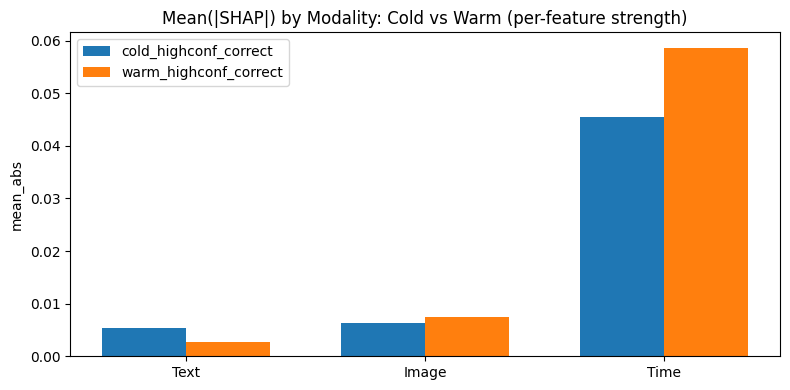

Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/explainability/shap_modality_importance_cold_warm_mean.png




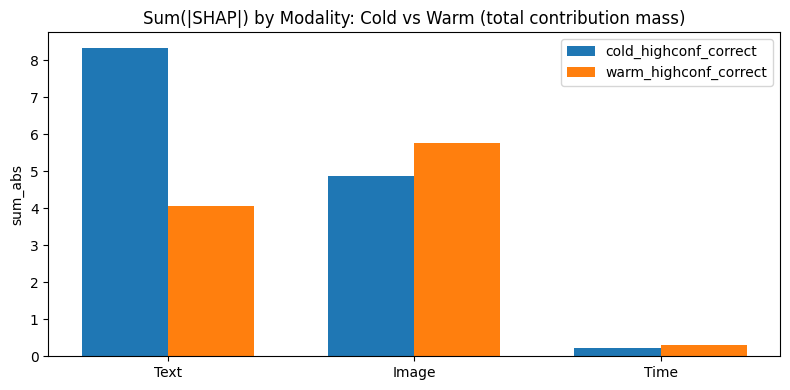

Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/explainability/shap_modality_importance_cold_warm_sum.png


In [132]:
# Cold vs Warm
plot_modality_bars(
    shap_sum, "cold_highconf_correct", "warm_highconf_correct", "mean_abs",
    "Mean(|SHAP|) by Modality: Cold vs Warm (per-feature strength)",
    os.path.join(explain_dir, "shap_modality_importance_cold_warm_mean.png")
)
print("\n")
plot_modality_bars(
    shap_sum, "cold_highconf_correct", "warm_highconf_correct", "sum_abs",
    "Sum(|SHAP|) by Modality: Cold vs Warm (total contribution mass)",
    os.path.join(explain_dir, "shap_modality_importance_cold_warm_sum.png")
)

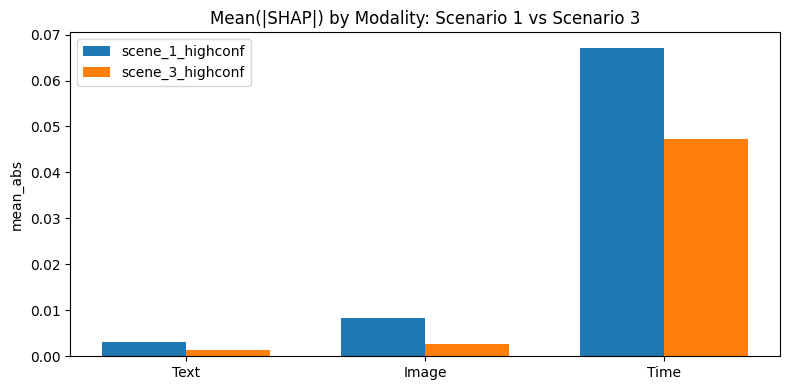

Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/explainability/shap_modality_importance_by_scene_mean.png




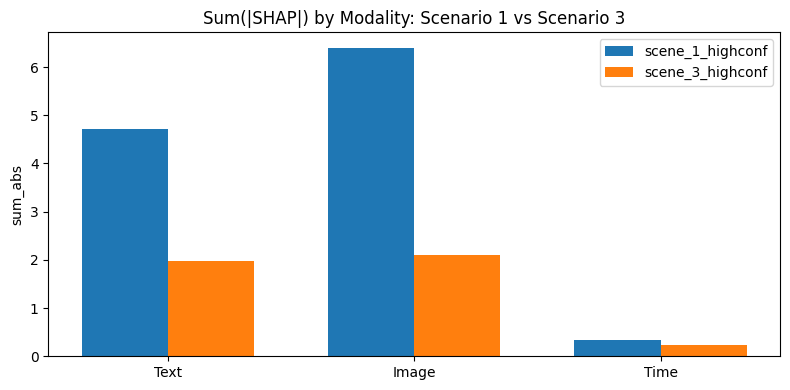

Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/explainability/shap_modality_importance_by_scene_sum.png


In [133]:
# Scenario 1 vs 3
plot_modality_bars(
    shap_sum, "scene_1_highconf", "scene_3_highconf", "mean_abs",
    "Mean(|SHAP|) by Modality: Scenario 1 vs Scenario 3",
    os.path.join(explain_dir, "shap_modality_importance_by_scene_mean.png")
)
print("\n")
plot_modality_bars(
    shap_sum, "scene_1_highconf", "scene_3_highconf", "sum_abs",
    "Sum(|SHAP|) by Modality: Scenario 1 vs Scenario 3",
    os.path.join(explain_dir, "shap_modality_importance_by_scene_sum.png")
)

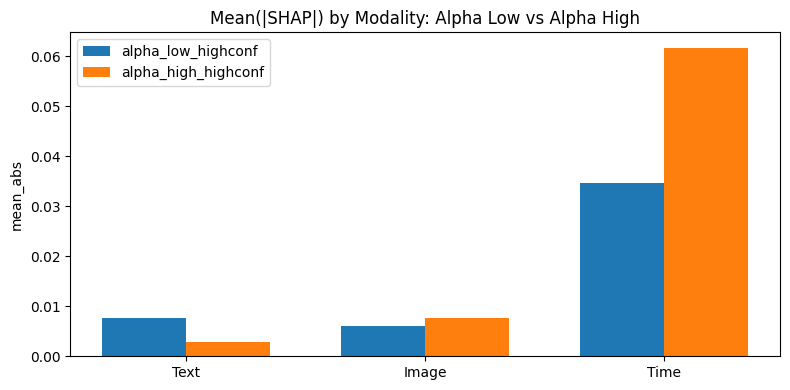

Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/explainability/shap_modality_importance_alpha_extremes_mean.png




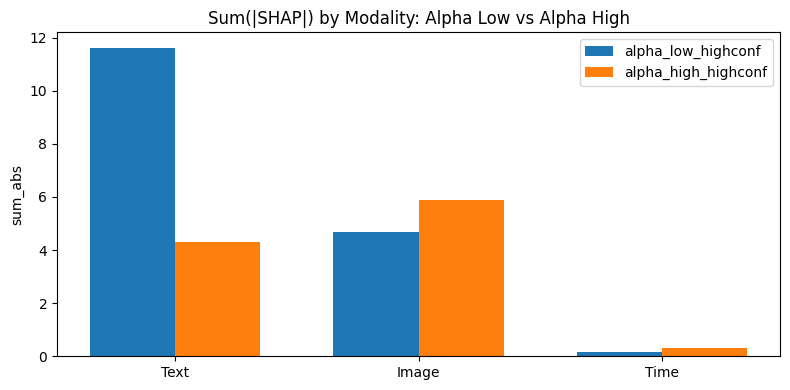

Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/explainability/shap_modality_importance_alpha_extremes_sum.png


In [130]:
# Alpha extremes
plot_modality_bars(
    shap_sum, "alpha_low_highconf", "alpha_high_highconf", "mean_abs",
    "Mean(|SHAP|) by Modality: Alpha Low vs Alpha High",
    os.path.join(explain_dir, "shap_modality_importance_alpha_extremes_mean.png")
)
print("\n")
plot_modality_bars(
    shap_sum, "alpha_low_highconf", "alpha_high_highconf", "sum_abs",
    "Sum(|SHAP|) by Modality: Alpha Low vs Alpha High",
    os.path.join(explain_dir, "shap_modality_importance_alpha_extremes_sum.png")
)

In [111]:
def load_per_row_modality_sums(cohort_name):
    fpath = os.path.join(explain_dir, f"shap_values_{cohort_name}.npz")
    data = np.load(fpath)
    rows = data["row_idx"]
    text = data["shap_text"]
    img  = data["shap_image"]
    time = data["shap_time"]

    text_sum = np.abs(text).sum(axis=1)
    img_sum  = np.abs(img).sum(axis=1)
    time_sum = np.abs(time).sum(axis=1)

    return pd.DataFrame({
        "row_idx": rows.astype(np.int64),
        "text_sum_abs_row": text_sum,
        "image_sum_abs_row": img_sum,
        "time_sum_abs_row": time_sum
    })

In [112]:
# Pick 1 example per key cohort (first row is fine; or choose max-confidence later)
pick_plan = [
    ("cold_highconf_correct", 1),
    ("cold_highconf_wrong", 1),
    ("warm_highconf_correct", 1),
    ("warm_highconf_wrong", 1),
    ("scene_3_highconf", 1),
]

In [113]:
case_rows = []
for cohort, k in pick_plan:
    per_row = load_per_row_modality_sums(cohort).head(k)
    per_row["cohort"] = cohort
    case_rows.append(per_row)

case_df = pd.concat(case_rows, ignore_index=True)

In [114]:
# Join with pred_df to fetch y_true/y_prob/scene/cold/alpha
case_df = case_df.merge(
    pred_df[["row_idx","y_true","y_prob","y_logit","scene_idx","cold_mask","alpha"]],
    on="row_idx",
    how="left"
)

In [115]:
# Determine top modality by total mass for the row
def top_modality(r):
    vals = {"text": r["text_sum_abs_row"], "image": r["image_sum_abs_row"], "time": r["time_sum_abs_row"]}
    return max(vals, key=vals.get)

case_df["top_modality"] = case_df.apply(top_modality, axis=1)

In [116]:
display(case_df)

,row_idx,text_sum_abs_row,image_sum_abs_row,time_sum_abs_row,cohort,y_true,y_prob,y_logit,scene_idx,cold_mask,alpha,top_modality
0,439064,8.097233,3.289830,0.152229,cold_highconf_correct,0.0,8.858584e-04,-7.028067,4,True,0.289065,text
1,1996768,5.817665,3.109337,0.325502,cold_highconf_wrong,1.0,7.916693e-03,-4.830833,0,True,0.578130,text
2,1878347,4.368397,6.073405,0.327758,warm_highconf_correct,0.0,4.816791e-07,-14.545987,1,False,1.000000,image
3,2836093,1.659980,1.430185,0.270274,warm_highconf_wrong,1.0,7.039832e-02,-2.580587,3,False,1.000000,text
4,203129,1.409993,1.764786,0.306908,scene_3_highconf,0.0,9.468458e-02,-2.257732,3,False,1.000000,image


In [117]:
# cold / high-confidence correct cases
case_rows = cohorts["cold_highconf_correct"]["case_row_idx"][:3]

# --- expected_value from background (your current code is fine) ---
with torch.no_grad():
    wrapper.set_context(
        user_idx=bg_context["user_idx"],
        item_idx=bg_context["item_idx"],
        scene_idx=bg_context["scene_idx"],
        item_count=bg_context["item_count"],
        cold_mask=bg_context["cold_mask"]
    )
    background_logits = wrapper(*bg_inputs).detach().cpu().numpy()
calculated_expected_value = float(background_logits.mean())

Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/explainability/shap_waterfall_row_1181497.png


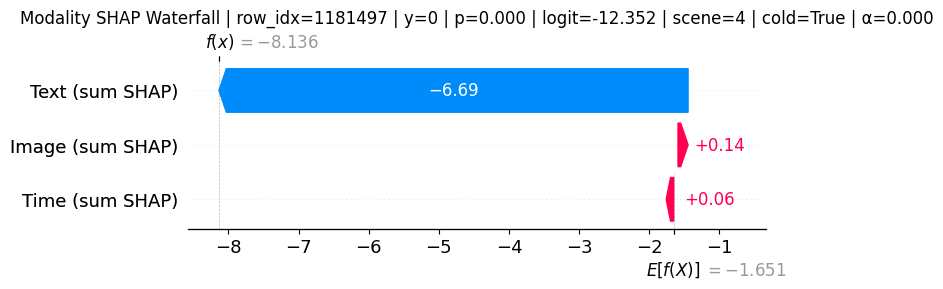



Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/explainability/shap_waterfall_row_3423235.png


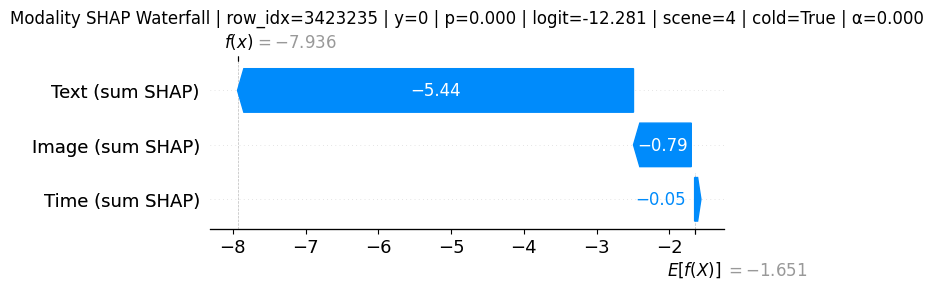



Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/explainability/shap_waterfall_row_2696676.png


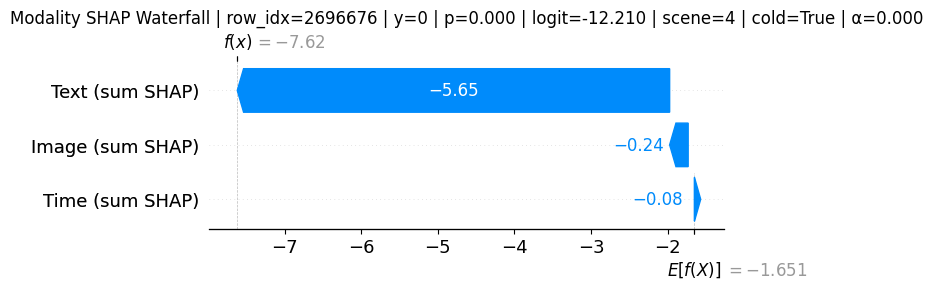

In [122]:
for row_idx in case_rows:
    batch = fetch_batch_by_row_idx(np.array([row_idx], dtype=np.int64))

    # context
    wrapper.set_context(
        user_idx=batch["user_idx"].to(device),
        item_idx=batch["item_idx"].to(device),
        scene_idx=batch["scene_idx"].to(device),
        item_count=batch["item_count"].to(device),
        cold_mask=batch["cold_mask"].to(device),
    )

    inputs = [
        batch["text_vec"].to(device),
        batch["image_vec"].to(device),
        batch["time_vec"].to(device),
    ]

    shap_vals = explainer.shap_values(inputs)

    # ---- IMPORTANT: normalize return type (GradientExplainer can return list for outputs) ----
    # We want arrays shaped (B=1, D)
    if isinstance(shap_vals, list) and len(shap_vals) == 1:
        shap_vals = shap_vals[0]

    shap_text = np.asarray(shap_vals[0])[0].reshape(-1)  # (1536,)
    shap_img  = np.asarray(shap_vals[1])[0].reshape(-1)  # (768,)
    shap_time = np.asarray(shap_vals[2])[0].reshape(-1)  # (5,)

    # ---- Modality-level signed contributions (directional, good for waterfall) ----
    text_contrib = float(shap_text.sum())
    img_contrib  = float(shap_img.sum())
    time_contrib = float(shap_time.sum())

    # predicted logit/prob for title (from wrapper to stay consistent)
    with torch.no_grad():
        logit = float(wrapper(*inputs).detach().cpu().numpy().reshape(-1)[0])
    prob = float(1.0 / (1.0 + np.exp(-logit)))

    # pull metadata for title
    # Fix: Get y_true from pred_df using row_idx, as 'label' is not in batch
    y_true = float(pred_df.loc[pred_df['row_idx'] == row_idx, 'y_true'].iloc[0])
    scene = int(batch["scene_idx"].cpu().numpy()[0])
    cold = bool(batch["cold_mask"].cpu().numpy()[0])
    alpha = float(model.get_last_alpha().detach().cpu().numpy().reshape(-1)[0]) if model.get_last_alpha() is not None else np.nan

    # ---- 3-feature SHAP waterfall ----
    exp_mod = shap.Explanation(
        values=np.array([text_contrib, img_contrib, time_contrib], dtype=np.float32),
        base_values=calculated_expected_value,
        feature_names=["Text (sum SHAP)", "Image (sum SHAP)", "Time (sum SHAP)"]
    )

    plt.figure()
    shap.waterfall_plot(exp_mod, max_display=3, show=False)
    plt.title(
        f"Modality SHAP Waterfall | row_idx={row_idx} | y={y_true:.0f} | p={prob:.3f} | "
        f"logit={logit:.3f} | scene={scene} | cold={cold} | α={alpha:.3f}"
    )
    plt.tight_layout()

    # Save plot to drive
    plot_out_path = os.path.join(explain_dir, f"shap_waterfall_row_{row_idx}.png")
    plt.savefig(plot_out_path, dpi=200)
    print(f"Saved: {plot_out_path}")
    plt.show()
    print("\n")

In [128]:
text_abs = float(np.abs(shap_text).sum())
img_abs  = float(np.abs(shap_img).sum())
time_abs = float(np.abs(shap_time).sum())

print({
    "row_idx": row_idx,
    "text_sum_signed": text_contrib, "image_sum_signed": img_contrib, "time_sum_signed": time_contrib,
    "text_sum_abs": text_abs, "image_sum_abs": img_abs, "time_sum_abs": time_abs,
})

{'row_idx': 2696676, 'text_sum_signed': -5.645399422111129, 'image_sum_signed': -0.24196005663665932, 'time_sum_signed': -0.08075153411263597, 'text_sum_abs': 16.930204064085107, 'image_sum_abs': 2.463016243554512, 'time_sum_abs': 0.12351634616969652}


In [134]:
%cd /content/drive/MyDrive/Final_Year_Project/Implementation


/content/drive/.shortcut-targets-by-id/1J-_B9dYFbtgqYmeg_SCsCplymxFmH7Pn/Final_Year_Project/Implementation
